In [1]:
# Replication analysis: 
# Load the BRFSS 2020 dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv("heart_2020_cleaned.csv")
print("Loaded successfully")
print(df.shape)
print(df.columns)
df.head()

Loaded successfully
(319795, 18)
Index(['HeartDisease', 'BMI', 'Smoking', 'AlcoholDrinking', 'Stroke',
       'PhysicalHealth', 'MentalHealth', 'DiffWalking', 'Sex', 'AgeCategory',
       'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth', 'SleepTime',
       'Asthma', 'KidneyDisease', 'SkinCancer'],
      dtype='object')


,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


In [2]:
# Initial data checks
df.dtypes

HeartDisease         object
BMI                 float64
Smoking              object
AlcoholDrinking      object
Stroke               object
PhysicalHealth      float64
MentalHealth        float64
DiffWalking          object
Sex                  object
AgeCategory          object
Race                 object
Diabetic             object
PhysicalActivity     object
GenHealth            object
SleepTime           float64
Asthma               object
KidneyDisease        object
SkinCancer           object
dtype: object

In [3]:
df.describe()

,BMI,PhysicalHealth,MentalHealth,SleepTime
count,319795.000000,319795.00000,319795.000000,319795.000000
mean,28.325399,3.37171,3.898366,7.097075
std,6.356100,7.95085,7.955235,1.436007
min,12.020000,0.00000,0.000000,1.000000
25%,24.030000,0.00000,0.000000,6.000000
50%,27.340000,0.00000,0.000000,7.000000
75%,31.420000,2.00000,3.000000,8.000000
max,94.850000,30.00000,30.000000,24.000000


In [4]:
# number of missing values in each column
df.isnull().sum()

HeartDisease        0
BMI                 0
Smoking             0
AlcoholDrinking     0
Stroke              0
PhysicalHealth      0
MentalHealth        0
DiffWalking         0
Sex                 0
AgeCategory         0
Race                0
Diabetic            0
PhysicalActivity    0
GenHealth           0
SleepTime           0
Asthma              0
KidneyDisease       0
SkinCancer          0
dtype: int64

In [5]:
# number of duplicate rows
df.duplicated().sum()

np.int64(18078)

In [6]:
# remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
print("After dropping duplicates:", df.shape)

After dropping duplicates: (301717, 18)


In [7]:
# Remove variables that are not used in this study
# Drop DiffWalking
df = df.drop(columns=['DiffWalking'] )
print(df.columns)

Index(['HeartDisease', 'BMI', 'Smoking', 'AlcoholDrinking', 'Stroke',
       'PhysicalHealth', 'MentalHealth', 'Sex', 'AgeCategory', 'Race',
       'Diabetic', 'PhysicalActivity', 'GenHealth', 'SleepTime', 'Asthma',
       'KidneyDisease', 'SkinCancer'],
      dtype='object')


In [8]:
# Drop Race and SkinCancer
df = df.drop(columns=['Race', 'SkinCancer'] )
print(df.columns)

Index(['HeartDisease', 'BMI', 'Smoking', 'AlcoholDrinking', 'Stroke',
       'PhysicalHealth', 'MentalHealth', 'Sex', 'AgeCategory', 'Diabetic',
       'PhysicalActivity', 'GenHealth', 'SleepTime', 'Asthma',
       'KidneyDisease'],
      dtype='object')


In [9]:
# Age categories
print(df['AgeCategory'].unique())

['55-59' '80 or older' '65-69' '75-79' '40-44' '70-74' '60-64' '50-54'
 '45-49' '18-24' '35-39' '30-34' '25-29']


In [10]:
# Keep men aged 45 and above
age_45plus = ['45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80 or older']

df_filtered = df[(df['Sex'] == 'Male') & (df['AgeCategory'].isin(age_45plus))].copy()
print(df_filtered.shape)

(94788, 15)


In [11]:
# Class distribution of heart disease
print(df_filtered['HeartDisease'].value_counts())
print(df_filtered['HeartDisease'].value_counts(normalize=True))

HeartDisease
No     79405
Yes    15383
Name: count, dtype: int64
HeartDisease
No     0.837712
Yes    0.162288
Name: proportion, dtype: float64


In [12]:
df_filtered = df_filtered.drop(columns=['Sex'])

In [13]:
print(df.columns)

Index(['HeartDisease', 'BMI', 'Smoking', 'AlcoholDrinking', 'Stroke',
       'PhysicalHealth', 'MentalHealth', 'Sex', 'AgeCategory', 'Diabetic',
       'PhysicalActivity', 'GenHealth', 'SleepTime', 'Asthma',
       'KidneyDisease'],
      dtype='object')


In [14]:
# List the categorical columns and their values
cat_cols = df_filtered.select_dtypes(include='object').columns.tolist()
cat_cols.remove('HeartDisease')  # target, handle separately

for col in cat_cols:
    print(col, ":", df_filtered[col].unique())

Smoking : ['Yes' 'No']
AlcoholDrinking : ['No' 'Yes']
Stroke : ['No' 'Yes']
AgeCategory : ['65-69' '60-64' '75-79' '70-74' '80 or older' '55-59' '50-54' '45-49']
Diabetic : ['Yes' 'No' 'No, borderline diabetes']
PhysicalActivity : ['Yes' 'No']
GenHealth : ['Fair' 'Good' 'Poor' 'Very good' 'Excellent']
Asthma : ['Yes' 'No']
KidneyDisease : ['No' 'Yes']


In [15]:
# Yes/No variables coded as 1/0
binary_cols = ['Smoking', 'AlcoholDrinking', 'Stroke', 'PhysicalActivity', 'Asthma', 'KidneyDisease']

for col in binary_cols:
    df_filtered[col] = df_filtered[col].map({'No': 0, 'Yes': 1})

In [16]:
# Diabetic coded as 0 = No, 1 = borderline, 2 = Yes
diabetic_map = {
    'No': 0,
    'No, borderline diabetes': 1,
    'Yes': 2
}
df_filtered['Diabetic'] = df_filtered['Diabetic'].map(diabetic_map)

In [17]:
# General health coded from 0 = Poor to 4 = Excellent
genhealth_map = {
    'Poor': 0,
    'Fair': 1,
    'Good': 2,
    'Very good': 3,
    'Excellent': 4
}
df_filtered['GenHealth'] = df_filtered['GenHealth'].map(genhealth_map)

In [18]:
# Age categories coded from 0 = 45-49 to 7 = 80 or older
age_map = {
    '45-49': 0,
    '50-54': 1,
    '55-59': 2,
    '60-64': 3,
    '65-69': 4,
    '70-74': 5,
    '75-79': 6,
    '80 or older': 7
}
df_filtered['AgeCategory'] = df_filtered['AgeCategory'].map(age_map)

In [19]:
# Target: heart disease coded as 1/0
df_filtered['HeartDisease'] = df_filtered['HeartDisease'].map({'No': 0, 'Yes': 1})

In [20]:
# Check data types and missing values after encoding
print(df_filtered.dtypes)
print(df_filtered.isnull().sum())

HeartDisease          int64
BMI                 float64
Smoking               int64
AlcoholDrinking       int64
Stroke                int64
PhysicalHealth      float64
MentalHealth        float64
AgeCategory           int64
Diabetic              int64
PhysicalActivity      int64
GenHealth             int64
SleepTime           float64
Asthma                int64
KidneyDisease         int64
dtype: object
HeartDisease        0
BMI                 0
Smoking             0
AlcoholDrinking     0
Stroke              0
PhysicalHealth      0
MentalHealth        0
AgeCategory         0
Diabetic            0
PhysicalActivity    0
GenHealth           0
SleepTime           0
Asthma              0
KidneyDisease       0
dtype: int64


In [21]:
# Train-test split and standardisation
# 80/20 stratified train-test split
# z-score standardisation fitted on the training set only

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = ['BMI', 'Smoking', 'AlcoholDrinking', 'Stroke', 'PhysicalHealth',
            'MentalHealth', 'AgeCategory', 'Diabetic', 'PhysicalActivity',
            'GenHealth', 'SleepTime', 'Asthma', 'KidneyDisease']
target = 'HeartDisease'

X = df_filtered[features]
y = df_filtered[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Train shape: (75830, 13)
Test shape: (18958, 13)


In [22]:
# SMOTE on the training data only

from imblearn.over_sampling import SMOTE

# hyperparameter tuning section
X_train_orig = X_train_scaled.copy()
y_train_orig = y_train.copy()

print("Before SMOTE:", y_train.value_counts().to_dict())

smote = SMOTE(sampling_strategy=0.3, random_state=42)
X_train_scaled, y_train = smote.fit_resample(X_train_scaled, y_train)

print("After SMOTE:", y_train.value_counts().to_dict())

Before SMOTE: {0: 63524, 1: 12306}
After SMOTE: {0: 63524, 1: 19057}


In [23]:
# Evaluation metrics
from sklearn.metrics import (accuracy_score, roc_auc_score, recall_score,
                               precision_score, f1_score, confusion_matrix,
                               brier_score_loss)

results = []

In [24]:
#LogisticRegression (default settings)
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

y_pred = lr_model.predict(X_test_scaled)
y_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Logistic Regression Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'Logistic Regression', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Logistic Regression Results
Accuracy:    0.8354
AUC-ROC:     0.7592
Sensitivity: 0.2372
Specificity: 0.9513
Precision:   0.4857
F1-Score:    0.3188
Brier Score: 0.1223
NPV:         0.8655


In [25]:
#Random Forest (default settings)
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model.fit(X_train_scaled, y_train)

y_pred = rf_model.predict(X_test_scaled)
y_proba = rf_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Random Forest Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'Random Forest', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Random Forest Results
Accuracy:    0.7996
AUC-ROC:     0.6877
Sensitivity: 0.2148
Specificity: 0.9129
Precision:   0.3234
F1-Score:    0.2582
Brier Score: 0.1453
NPV:         0.8572


In [26]:
#XGBoost (default settings)
import xgboost as xgb

xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_scaled, y_train)

y_pred = xgb_model.predict(X_test_scaled)
y_proba = xgb_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("XGBoost Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'XGBoost', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

XGBoost Results
Accuracy:    0.8367
AUC-ROC:     0.7474
Sensitivity: 0.1349
Specificity: 0.9727
Precision:   0.4894
F1-Score:    0.2115
Brier Score: 0.1213
NPV:         0.8530


In [27]:
#CatBoost (default settings)
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(random_state=42, verbose=0)
cat_model.fit(X_train_scaled, y_train)

y_pred = cat_model.predict(X_test_scaled)
y_proba = cat_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("CatBoost Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'CatBoost', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

CatBoost Results
Accuracy:    0.8382
AUC-ROC:     0.7537
Sensitivity: 0.1319
Specificity: 0.9751
Precision:   0.5062
F1-Score:    0.2093
Brier Score: 0.1199
NPV:         0.8529


In [28]:
#MLP (default settings)
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(random_state=42, max_iter=500)
mlp_model.fit(X_train_scaled, y_train)

y_pred = mlp_model.predict(X_test_scaled)
y_proba = mlp_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("MLP Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'MLP', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

MLP Results
Accuracy:    0.8298
AUC-ROC:     0.7491
Sensitivity: 0.2392
Specificity: 0.9442
Precision:   0.4538
F1-Score:    0.3133
Brier Score: 0.1261
NPV:         0.8650


In [29]:
#KNN (default settings)
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train)

y_pred = knn_model.predict(X_test_scaled)
y_proba = knn_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("KNN Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'KNN', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

KNN Results
Accuracy:    0.7864
AUC-ROC:     0.6613
Sensitivity: 0.2808
Specificity: 0.8843
Precision:   0.3199
F1-Score:    0.2991
Brier Score: 0.1579
NPV:         0.8639


In [30]:
#Decision Tree (default settings)
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

y_pred = dt_model.predict(X_test_scaled)
y_proba = dt_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("Decision Tree Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'Decision Tree', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

Decision Tree Results
Accuracy:    0.7526
AUC-ROC:     0.5612
Sensitivity: 0.2831
Specificity: 0.8435
Precision:   0.2595
F1-Score:    0.2708
Brier Score: 0.2495
NPV:         0.8586


In [31]:
#AdaBoost (default settings)
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(X_train_scaled, y_train)

y_pred = ada_model.predict(X_test_scaled)
y_proba = ada_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
sens = recall_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
brier = brier_score_loss(y_test, y_proba)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)
npv = tn / (tn + fn)

print("AdaBoost Results")
print(f"Accuracy:    {acc:.4f}")
print(f"AUC-ROC:     {auc:.4f}")
print(f"Sensitivity: {sens:.4f}")
print(f"Specificity: {spec:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"F1-Score:    {f1:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"NPV:         {npv:.4f}")

results.append({'Model': 'AdaBoost', 'Accuracy': acc, 'AUC-ROC': auc,
                 'Sensitivity': sens, 'Specificity': spec, 'Precision': prec,
                 'F1-Score': f1, 'Brier Score': brier, 'NPV': npv})

AdaBoost Results
Accuracy:    0.8368
AUC-ROC:     0.7559
Sensitivity: 0.2350
Specificity: 0.9535
Precision:   0.4945
F1-Score:    0.3186
Brier Score: 0.1715
NPV:         0.8655


In [32]:
# Table of default-model results
results_df = pd.DataFrame(results)
results_df = results_df.drop_duplicates(subset='Model', keep='first').reset_index(drop=True)
results_df = results_df.sort_values(by='AUC-ROC', ascending=False).reset_index(drop=True)
results_df.to_csv("baseline_model_results_full2.csv", index=False)
results_df

,Model,Accuracy,AUC-ROC,Sensitivity,Specificity,Precision,F1-Score,Brier Score,NPV
0,Logistic Regression,0.835426,0.759167,0.237244,0.951325,0.485695,0.318777,0.122299,0.865540
1,AdaBoost,0.836850,0.755939,0.234969,0.953466,0.494528,0.318572,0.171475,0.865455
2,CatBoost,0.838221,0.753719,0.131947,0.975065,0.506234,0.209332,0.119911,0.852886
3,MLP,0.829782,0.749079,0.239194,0.944210,0.453761,0.313258,0.126116,0.864963
4,XGBoost,0.836744,0.747395,0.134872,0.972735,0.489387,0.211465,0.121342,0.853009
5,Random Forest,0.799610,0.687652,0.214820,0.912915,0.323386,0.258153,0.145331,0.857160
6,KNN,0.786370,0.661261,0.280793,0.884327,0.319882,0.299065,0.157909,0.863874
7,Decision Tree,0.752558,0.561233,0.283068,0.843524,0.259535,0.270791,0.249455,0.858608


In [33]:
# Hyperparameter tuning with SMOTE inside the cross-validation pipeline

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    brier_score_loss,
    confusion_matrix
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from imblearn.pipeline import Pipeline as ImbPipeline


In [34]:
# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [35]:
# Function that evaluates a fitted model on the test set
def evaluate_model(model_name, fitted_model, X_test, y_test):
    y_pred = fitted_model.predict(X_test)
    y_proba = fitted_model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_proba),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Brier Score": brier_score_loss(y_test, y_proba),
        "NPV": npv
    }

In [36]:
# Logistic Regression: parameter grid
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

param_grid_lr = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "clf__solver": ["liblinear", "lbfgs"],
    "clf__penalty": ["l2"]
}


In [37]:
# Random Forest
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

param_grid_rf = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [5, 10, 15],
    "clf__min_samples_split": [2, 10],
    "clf__min_samples_leaf": [1, 2],
    "clf__max_features": ["sqrt"]
}


In [38]:
# XGBoost
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=1
)

param_grid_xgb = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [3, 5, 7],
    "clf__learning_rate": [0.05, 0.1],
    "clf__subsample": [1.0],
    "clf__colsample_bytree": [1.0]
}


In [39]:
# CatBoost
cat_model = CatBoostClassifier(
    verbose=0,
    random_seed=42,
    thread_count=1,
    loss_function="Logloss"
)

param_grid_cat = {
    "clf__iterations": [100, 200],
    "clf__depth": [4, 6, 8],
    "clf__learning_rate": [0.05, 0.1],
    "clf__l2_leaf_reg": [3]
}


In [40]:
# MLP
mlp = MLPClassifier(
    max_iter=300,
    early_stopping=True,
    random_state=42
)

param_grid_mlp = {
    "clf__hidden_layer_sizes": [(32,), (64,), (64, 32)],
    "clf__activation": ["relu"],
    "clf__alpha": [0.0001, 0.001],
    "clf__learning_rate_init": [0.001, 0.01]
}


In [41]:
# KNN
knn = KNeighborsClassifier(
    n_jobs=1
)

param_grid_knn = {
    "clf__n_neighbors": [3, 5, 7, 11, 15],
    "clf__weights": ["uniform", "distance"],
    "clf__p": [1, 2]
}


In [42]:
# Decision Tree
dt = DecisionTreeClassifier(
    random_state=42
)

param_grid_dt = {
    "clf__max_depth": [5, 10, 15, None],
    "clf__min_samples_split": [2, 10],
    "clf__min_samples_leaf": [1, 5],
    "clf__criterion": ["gini", "entropy"]
}


In [43]:
# AdaBoost
ada = AdaBoostClassifier(
    random_state=42
)

param_grid_ada = {
    "clf__n_estimators": [50, 100, 200],
    "clf__learning_rate": [0.01, 0.1, 1.0]
}


In [44]:
# Pipeline (SMOTE then classifier) and a GridSearchCV object for each model
smote = SMOTE(sampling_strategy=0.3, random_state=42)

def make_pipeline(clf):
    return ImbPipeline(steps=[("smote", smote), ("clf", clf)])

searches = {
    "Logistic Regression": GridSearchCV(
        estimator=make_pipeline(lr),
        param_grid=param_grid_lr,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    ),

    "Random Forest": GridSearchCV(
        estimator=make_pipeline(rf),
        param_grid=param_grid_rf,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    ),

    "XGBoost": GridSearchCV(
        estimator=make_pipeline(xgb_model),
        param_grid=param_grid_xgb,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    ),

    "CatBoost": GridSearchCV(
        estimator=make_pipeline(cat_model),
        param_grid=param_grid_cat,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    ),

    "MLP": GridSearchCV(
        estimator=make_pipeline(mlp),
        param_grid=param_grid_mlp,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    ),

    "KNN": GridSearchCV(
        estimator=make_pipeline(knn),
        param_grid=param_grid_knn,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    ),

    "Decision Tree": GridSearchCV(
        estimator=make_pipeline(dt),
        param_grid=param_grid_dt,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    ),

    "AdaBoost": GridSearchCV(
        estimator=make_pipeline(ada),
        param_grid=param_grid_ada,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )
}


In [45]:
best_models = {}
grid_results = []

In [46]:
# Run the grid search for each model on the original training data, then evaluate on the test set

for model_name, search in searches.items():

    print(f"\n{'=' * 70}")
    print(f"Running GridSearchCV for: {model_name}")
    print(f"{'=' * 70}")

    search.fit(X_train_orig, y_train_orig)

    best_models[model_name] = search.best_estimator_

    print("Best parameters:")
    print(search.best_params_)

    print(f"Best mean CV ROC-AUC: {search.best_score_:.4f}")

    result = evaluate_model(
        model_name=f"{model_name} (GridSearchCV)",
        fitted_model=search.best_estimator_,
        X_test=X_test_scaled,
        y_test=y_test
    )

    result["Best CV ROC-AUC"] = search.best_score_
    result["Best Parameters"] = search.best_params_

    grid_results.append(result)



Running GridSearchCV for: Logistic Regression
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters:
{'clf__C': 0.001, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
Best mean CV ROC-AUC: 0.7656

Running GridSearchCV for: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters:
{'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Best mean CV ROC-AUC: 0.7640

Running GridSearchCV for: XGBoost
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters:
{'clf__colsample_bytree': 1.0, 'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 1.0}
Best mean CV ROC-AUC: 0.7659

Running GridSearchCV for: CatBoost
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters:
{'clf__depth': 6, 'clf__iterations': 200, 'clf__l2_leaf_reg': 3, 'clf__learning_rate': 0.05}
Best mean CV ROC-

In [47]:
# Table of tuned-model results
grid_results_df = pd.DataFrame(grid_results)

# Remove duplicate model results
grid_results_df = grid_results_df.drop_duplicates(
    subset=["Model"]
).reset_index(drop=True)

# Sort by AUC-ROC
grid_results_df = grid_results_df.sort_values(
    by="AUC-ROC",
    ascending=False
).reset_index(drop=True)

display(grid_results_df)

,Model,Accuracy,AUC-ROC,Sensitivity,Specificity,Precision,F1-Score,Brier Score,NPV,Best CV ROC-AUC,Best Parameters
0,CatBoost (GridSearchCV),0.841808,0.760168,0.131297,0.979472,0.553425,0.212241,0.118824,0.853357,0.766955,"{'clf__depth': 6, 'clf__iterations': 200, 'clf..."
1,Logistic Regression (GridSearchCV),0.835742,0.759243,0.236594,0.951829,0.487609,0.318600,0.123990,0.865502,0.765634,"{'clf__C': 0.001, 'clf__penalty': 'l2', 'clf__..."
2,XGBoost (GridSearchCV),0.841175,0.759164,0.133247,0.978339,0.543767,0.214043,0.119131,0.853494,0.765857,"{'clf__colsample_bytree': 1.0, 'clf__learning_..."
3,Random Forest (GridSearchCV),0.839804,0.759051,0.138772,0.975631,0.524570,0.219481,0.120460,0.853946,0.763985,"{'clf__max_depth': 10, 'clf__max_features': 's..."
4,MLP (GridSearchCV),0.835215,0.758738,0.235944,0.951325,0.484323,0.317308,0.123251,0.865342,0.765972,"{'clf__activation': 'relu', 'clf__alpha': 0.00..."
5,AdaBoost (GridSearchCV),0.837536,0.756924,0.204745,0.960141,0.498812,0.290323,0.196994,0.861712,0.763339,"{'clf__learning_rate': 1.0, 'clf__n_estimators..."
6,Decision Tree (GridSearchCV),0.838063,0.742098,0.116672,0.977835,0.504923,0.189546,0.123457,0.851044,0.745435,"{'clf__criterion': 'gini', 'clf__max_depth': 1..."
7,KNN (GridSearchCV),0.817439,0.706646,0.243094,0.928720,0.397872,0.301795,0.136051,0.863626,0.713971,"{'clf__n_neighbors': 15, 'clf__p': 1, 'clf__we..."


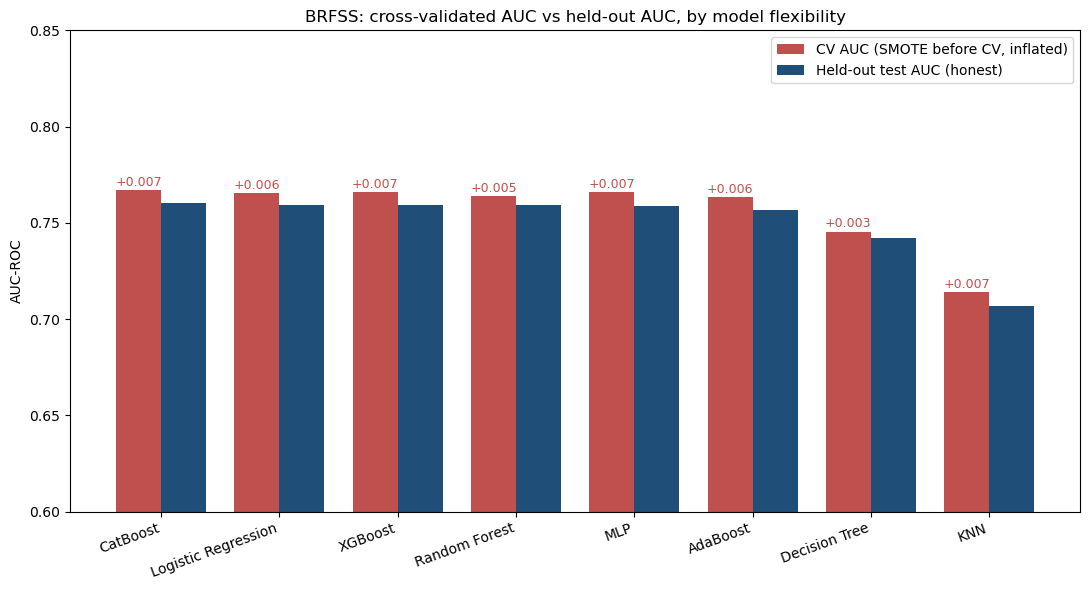

In [48]:
# Cross-Validated vs test AUC-ROC for the tuned model

plot_df = grid_results_df.copy()
plot_df['Model'] = plot_df['Model'].str.replace(' (GridSearchCV)', '', regex=False)

x = np.arange(len(plot_df))
width = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - width/2, plot_df['Best CV ROC-AUC'], width,
            label='CV AUC (SMOTE before CV, inflated)', color='#C0504D')
b2 = ax.bar(x + width/2, plot_df['AUC-ROC'], width,
            label='Held-out test AUC (honest)', color='#1F4E79')

# Label the gap above each CV bar
for bar, cv_val, test_val in zip(b1, plot_df['Best CV ROC-AUC'], plot_df['AUC-ROC']):
    gap = cv_val - test_val
    ax.annotate(f'+{gap:.3f}',
                xy=(bar.get_x() + bar.get_width() / 2, cv_val),
                xytext=(0, 3), textcoords="offset points",
                ha='center', fontsize=9, color='#C0504D')

ax.set_xticks(x)
ax.set_xticklabels(plot_df['Model'], rotation=20, ha='right')
ax.set_ylabel('AUC-ROC')
ax.set_title('BRFSS: cross-validated AUC vs held-out AUC, by model flexibility')
ax.set_ylim(0.60, 0.85)
ax.legend()
plt.tight_layout()
plt.savefig('brfss_cv_gap_verified.png', dpi=300)
plt.show()

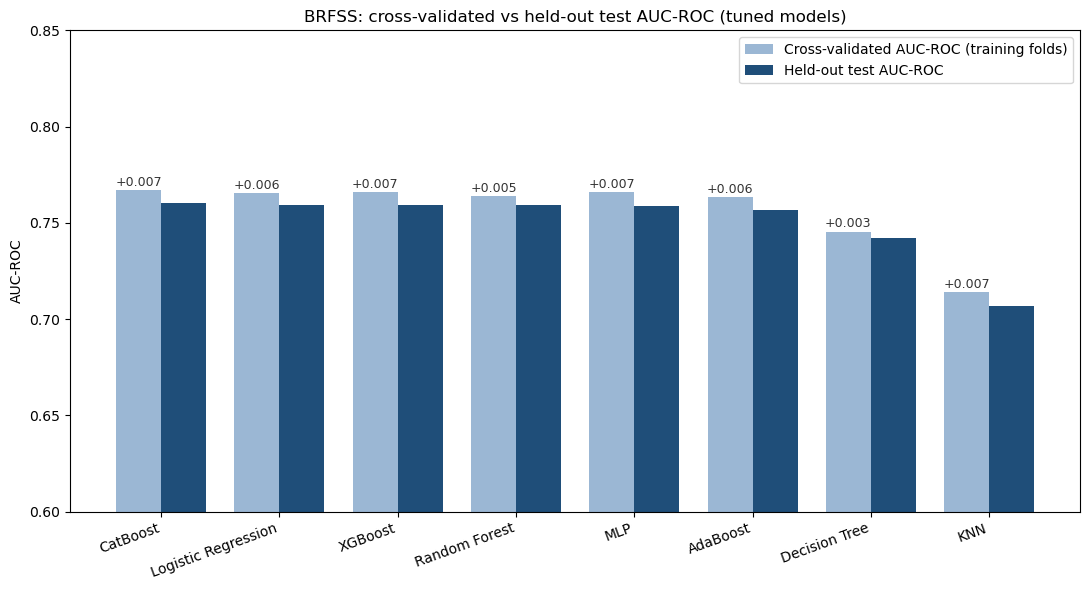

In [49]:
plot_df = grid_results_df.copy()
plot_df['Model'] = plot_df['Model'].str.replace(' (GridSearchCV)', '', regex=False)

x = np.arange(len(plot_df))
width = 0.38

fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - width/2, plot_df['Best CV ROC-AUC'], width,
            label='Cross-validated AUC-ROC (training folds)', color='#9BB7D4')
b2 = ax.bar(x + width/2, plot_df['AUC-ROC'], width,
            label='Held-out test AUC-ROC', color='#1F4E79')

# Show the difference (CV minus test) above each CV bar
for bar, cv_val, test_val in zip(b1, plot_df['Best CV ROC-AUC'], plot_df['AUC-ROC']):
    gap = cv_val - test_val
    ax.annotate(f'{gap:+.3f}',
                xy=(bar.get_x() + bar.get_width() / 2, cv_val),
                xytext=(0, 3), textcoords="offset points",
                ha='center', fontsize=9, color='#333333')

ax.set_xticks(x)
ax.set_xticklabels(plot_df['Model'], rotation=20, ha='right')
ax.set_ylabel('AUC-ROC')
ax.set_title('BRFSS: cross-validated vs held-out test AUC-ROC (tuned models)')
ax.set_ylim(0.60, 0.85)
ax.legend()
plt.tight_layout()
plt.savefig('brfss_cv_vs_test_auc.png', dpi=300)
plt.show()